<a href="https://colab.research.google.com/github/Angela-Benedict/ds2002-fa26/blob/main/notebooks/walmart-hurricane-project/noor_weather_api.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Q3 · Weather and Sales
### Noor Imat



---

In [1]:
import pandas as pd
import numpy as np
import requests
import time

### Load transaction data

In [2]:
transactions = pd.read_csv(
    "https://raw.githubusercontent.com/Angela-Benedict/ds2002-fa26/refs/heads/main/notebooks/walmart-hurricane-project/data/walmart_transactions.csv"
)

transactions.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
0,TXN012636,FL-710,2024-09-13T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15
1,TXN000759,fl-412,2024-09-02 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02
2,TXN003338,FL-105,2024-09-06 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47
3,TXN025020,FL-330,2024-09-30 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59
4,TXN015797,FL-302,2024-09-15 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82


### Prepare sales dates for the weather join
Convert the mixed-format transaction timestamps to datetime values and create a normalized daily `date` column for joining with the weather data.

In [3]:
def prepare_sales_for_weather_join(sales_df, timestamp_col):
    sales = sales_df.copy()

    sales[timestamp_col] = pd.to_datetime(
    sales[timestamp_col],
    format="mixed",
    errors="coerce"
)

    sales["date"] = sales[timestamp_col].dt.normalize()

    print("Rows:", len(sales))
    print("Date range:", sales["date"].min(), "to", sales["date"].max())
    print("Missing dates:", sales["date"].isna().sum())

    return sales

In [4]:
sales_prepared = prepare_sales_for_weather_join(
    transactions,
    "timestamp"
)

sales_prepared.head()

Rows: 25562
Date range: 2024-09-01 00:00:00 to 2024-09-30 00:00:00
Missing dates: 886


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,date
0,TXN012636,FL-710,2024-09-13 09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,2024-09-13
1,TXN000759,fl-412,2024-09-02 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02,2024-09-02
2,TXN003338,FL-105,2024-09-06 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47,2024-09-06
3,TXN025020,FL-330,2024-09-30 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59,2024-09-30
4,TXN015797,FL-302,2024-09-15 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82,2024-09-15


### Aggregate sales by day

Group the prepared transactions by date to calculate the number of orders per day for the weather analysis.

In [5]:
daily_sales = (
    sales_prepared
    .dropna(subset=["date"])
    .groupby("date")
    .size()
    .reset_index(name="orders")
)

print("Days of sales:", len(daily_sales))
print("Date range:", daily_sales["date"].min(), "to", daily_sales["date"].max())

daily_sales.head()

Days of sales: 30
Date range: 2024-09-01 00:00:00 to 2024-09-30 00:00:00


,date,orders
0,2024-09-01,587
1,2024-09-02,581
2,2024-09-03,586
3,2024-09-04,566
4,2024-09-05,809


### Fetch daily weather data

Retrieve daily precipitation, maximum wind speed, and surface pressure for Orlando from the Open-Meteo Historical Weather API. The request uses the `America/New_York` timezone to align the weather data with the sales dates. Hourly surface pressure is aggregated to a daily mean.

**Source:** Open-Meteo Historical Weather API  
**Base URL:** https://archive-api.open-meteo.com/v1/archive

In [6]:
BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {
        'latitude': lat,
        'longitude': lon,
        'start_date': start,
        'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max',
        'hourly': 'surface_pressure',
        'timezone': 'America/New_York',
    }

    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue

        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue

        r.raise_for_status()
        data = r.json()

        # Daily precipitation and wind
        frame = pd.DataFrame(data['daily'])
        frame = frame.rename(columns={'time': 'date'})
        frame['date'] = pd.to_datetime(frame['date'])

        # Hourly pressure -> daily mean pressure
        pressure = pd.DataFrame(data['hourly'])
        pressure['time'] = pd.to_datetime(pressure['time'])
        pressure['date'] = pressure['time'].dt.normalize()

        daily_pressure = (
            pressure
            .groupby('date', as_index=False)['surface_pressure']
            .mean()
            .rename(columns={'surface_pressure': 'surface_pressure_mean'})
        )

        frame = frame.merge(
            daily_pressure,
            on='date',
            how='left'
        )

        frame['source'] = 'open-meteo'
        return frame


try:
    weather_live = daily_weather('2024-09-01', '2024-09-30')
except requests.RequestException as err:
    print('API call failed:', err)
    raise

print('source:', weather_live['source'].iloc[0])
weather_live.head()

source: open-meteo


,date,precipitation_sum,windspeed_10m_max,surface_pressure_mean,source
0,2024-09-01,3.0,18.8,1009.608333,open-meteo
1,2024-09-02,12.4,13.5,1009.575000,open-meteo
2,2024-09-03,24.8,22.8,1011.066667,open-meteo
3,2024-09-04,22.1,15.5,1013.229167,open-meteo
4,2024-09-05,22.7,15.2,1012.800000,open-meteo


### Join sales and weather data

Merge the daily sales counts with the daily weather data by date, then verify that the join preserves all sales rows and does not introduce missing weather values.

In [7]:
sales_weather = daily_sales.merge(
    weather_live,
    on="date",
    how="left"
)

print("Sales rows before join:", len(daily_sales))
print("Rows after join:", len(sales_weather))
print("Missing weather rows:", sales_weather["precipitation_sum"].isna().sum())

sales_weather.head()

Sales rows before join: 30
Rows after join: 30
Missing weather rows: 0


,date,orders,precipitation_sum,windspeed_10m_max,surface_pressure_mean,source
0,2024-09-01,587,3.0,18.8,1009.608333,open-meteo
1,2024-09-02,581,12.4,13.5,1009.575000,open-meteo
2,2024-09-03,586,24.8,22.8,1011.066667,open-meteo
3,2024-09-04,566,22.1,15.5,1013.229167,open-meteo
4,2024-09-05,809,22.7,15.2,1012.800000,open-meteo


### Check same-day weather correlations

Calculate the correlation between daily orders, precipitation, maximum wind speed, and mean surface pressure to see whether sales move with same-day weather conditions.

In [8]:
sales_weather[
    [
        "orders",
        "precipitation_sum",
        "windspeed_10m_max",
        "surface_pressure_mean"
    ]
].corr()

,orders,precipitation_sum,windspeed_10m_max,surface_pressure_mean
orders,1.000000,0.011556,-0.241560,0.013432
precipitation_sum,0.011556,1.000000,-0.045795,0.240696
windspeed_10m_max,-0.241560,-0.045795,1.000000,-0.701828
surface_pressure_mean,0.013432,0.240696,-0.701828,1.000000


In [9]:
sales_weather[
    (sales_weather["date"] >= "2024-09-10") &
    (sales_weather["date"] <= "2024-09-16")
]

,date,orders,precipitation_sum,windspeed_10m_max,surface_pressure_mean,source
9,2024-09-10,1314,14.4,14.3,1009.908333,open-meteo
10,2024-09-11,1369,12.0,15.8,1007.950000,open-meteo
11,2024-09-12,1375,0.4,12.1,1007.245833,open-meteo
12,2024-09-13,1973,0.9,10.4,1008.170833,open-meteo
13,2024-09-14,2011,21.1,17.4,1007.737500,open-meteo
14,2024-09-15,1140,1.2,9.0,1007.245833,open-meteo
15,2024-09-16,852,7.7,13.3,1008.362500,open-meteo


### Check lagged weather correlations

Compare daily orders with maximum wind speed shifted from -14 to +14 days to see whether the strongest relationship occurs before, during, or after the weather conditions.

In [10]:
lag_results = []

for lag in range(-14, 15):
    shifted_wind = sales_weather["windspeed_10m_max"].shift(lag)

    valid_pairs = sales_weather["orders"].notna() & shifted_wind.notna()

    corr = sales_weather.loc[valid_pairs, "orders"].corr(
        shifted_wind[valid_pairs]
    )

    lag_results.append({
        "lag": lag,
        "correlation": corr,
        "n_pairs": valid_pairs.sum()
    })

lag_results = pd.DataFrame(lag_results)
lag_results

,lag,correlation,n_pairs
0,-14,0.673313,16
1,-13,0.874986,17
2,-12,0.695619,18
3,-11,0.346413,19
4,-10,0.126367,20
5,-9,0.005747,21
6,-8,-0.119699,22
7,-7,-0.192759,23
8,-6,-0.254775,24
9,-5,-0.308350,25


In [11]:
best_lag = lag_results.loc[
    lag_results["correlation"].abs().idxmax()
]

print("Strongest lag:", int(best_lag["lag"]))
print("Correlation:", round(best_lag["correlation"], 3))

Strongest lag: -13
Correlation: 0.875


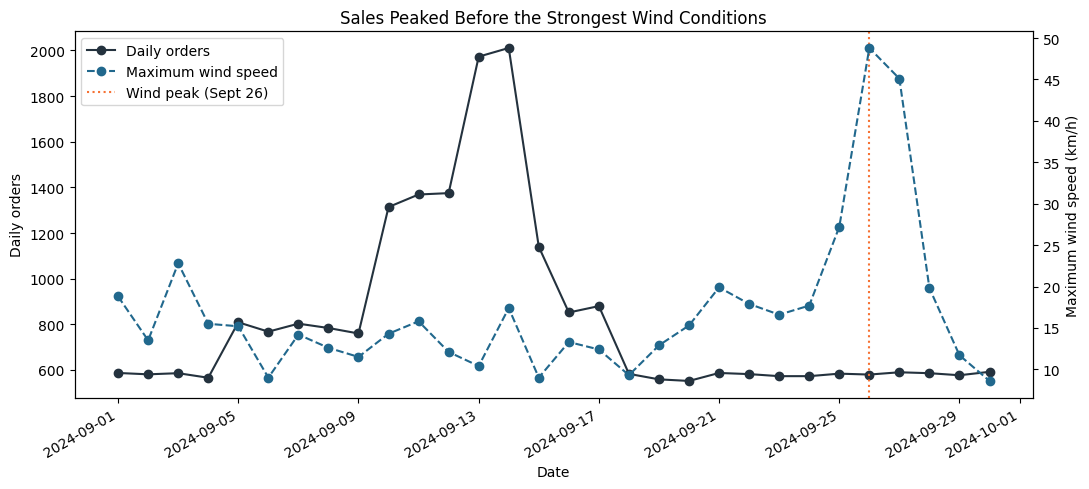

In [12]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(11, 5))

sales_line = ax1.plot(
    sales_weather["date"],
    sales_weather["orders"],
    marker="o",
    color="#24323E",
    label="Daily orders"
)
ax1.set_xlabel("Date")
ax1.set_ylabel("Daily orders")

ax2 = ax1.twinx()

wind_line = ax2.plot(
    sales_weather["date"],
    sales_weather["windspeed_10m_max"],
    marker="o",
    linestyle="--",
    color="#21688D",
    label="Maximum wind speed"
)
ax2.set_ylabel("Maximum wind speed (km/h)")

wind_peak = ax1.axvline(
    pd.Timestamp("2024-09-26"),
    color="#F67132",
    linestyle=":",
    label="Wind peak (Sept 26)"
)

lines = sales_line + wind_line + [wind_peak]
labels = [line.get_label() for line in lines]
ax1.legend(lines, labels, loc="upper left")

plt.title("Sales Peaked Before the Strongest Wind Conditions")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [13]:
category_map = {
    "emergency": "Emergency",
    "emergency supplies": "Emergency",
    "groceries": "Grocery",
    "grocery": "Grocery",
    "electronics": "Electronics",
    "entertainment": "Entertainment",
    "games & entertainment": "Entertainment",
    "household": "Household",
    "household essentials": "Household",
    "baby": "Baby",
    "baby products": "Baby",
    "breakfast": "Breakfast",
    "breakfast foods": "Breakfast",
    "alcohol": "Alcohol",
    "alcoholic beverages": "Alcohol",
    "snacks": "Snacks",
    "health": "Health",
    "health & wellness": "Health"
}

sales_prepared["category_clean"] = (
    sales_prepared["category"]
    .str.strip()
    .str.lower()
    .map(category_map)
)

sales_prepared["category_clean"].value_counts()

,count
category_clean,
Emergency,7195
Grocery,3315
Entertainment,2541
Electronics,2526
Household,2351
Baby,2090
Breakfast,2063
Alcohol,1269
Health,1231


In [14]:
daily_category_sales = (
    sales_prepared
    .dropna(subset=["date", "category_clean"])
    .groupby(["date", "category_clean"])
    .size()
    .reset_index(name="orders")
)

category_weather = daily_category_sales.merge(
    weather_live,
    on="date",
    how="left"
)

category_weather.head()

,date,category_clean,orders,precipitation_sum,windspeed_10m_max,surface_pressure_mean,source
0,2024-09-01,Alcohol,29,3.0,18.8,1009.608333,open-meteo
1,2024-09-01,Baby,61,3.0,18.8,1009.608333,open-meteo
2,2024-09-01,Breakfast,31,3.0,18.8,1009.608333,open-meteo
3,2024-09-01,Electronics,54,3.0,18.8,1009.608333,open-meteo
4,2024-09-01,Emergency,155,3.0,18.8,1009.608333,open-meteo


In [15]:
category_correlations = (
    category_weather
    .groupby("category_clean")
    .apply(
        lambda x: pd.Series({
            "precipitation_corr": x["orders"].corr(x["precipitation_sum"]),
            "wind_corr": x["orders"].corr(x["windspeed_10m_max"]),
            "pressure_corr": x["orders"].corr(x["surface_pressure_mean"])
        }),
        include_groups=False
    )
    .round(3)
)

category_correlations

,precipitation_corr,wind_corr,pressure_corr
category_clean,,,
Alcohol,-0.010,-0.199,0.010
Baby,0.014,-0.243,0.056
Breakfast,0.051,-0.231,-0.007
Electronics,-0.013,-0.241,0.030
Emergency,-0.007,-0.252,0.012
Entertainment,0.018,-0.211,-0.041
Grocery,0.051,-0.241,0.067
Health,-0.031,-0.233,-0.021
Household,0.056,-0.232,0.036


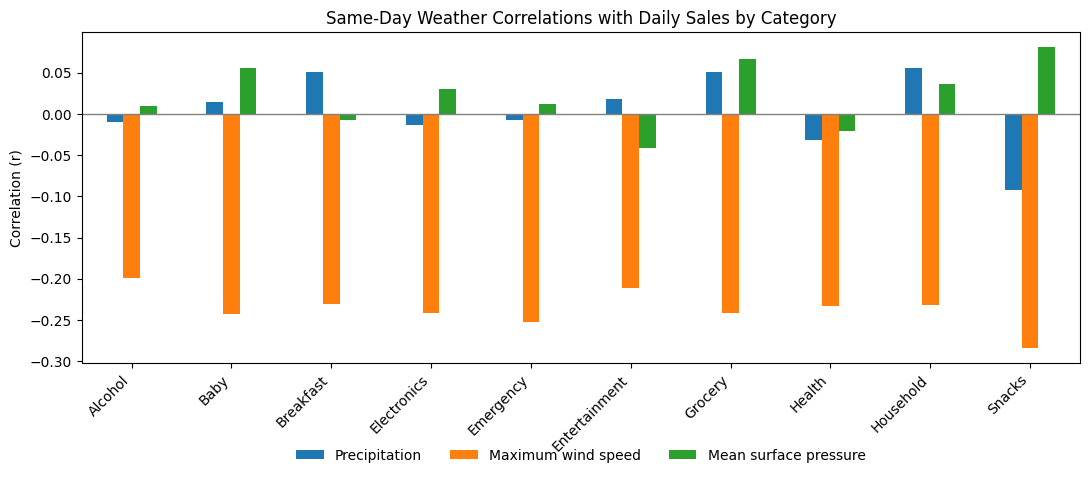

In [16]:
ax = category_correlations.rename(columns={
    "precipitation_corr": "Precipitation",
    "wind_corr": "Maximum wind speed",
    "pressure_corr": "Mean surface pressure",
}).plot(
    kind="bar",
    figsize=(11, 5)
)

ax.axhline(0, color="gray", linewidth=1)

ax.set_title("Same-Day Weather Correlations with Daily Sales by Category")
ax.set_xlabel("")
ax.set_ylabel("Correlation (r)")

plt.xticks(rotation=45, ha="right")
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.22),
    ncol=3,
    frameon=False
)

plt.tight_layout()
plt.show()

### Q3: Weather and Sales

Daily sales showed almost no relationship with same-day precipitation (r = 0.012, n = 30) or mean surface pressure (r = 0.013, n = 30), while maximum wind speed had a weak negative relationship with sales (r = -0.242, n = 30). The category-level results showed the same general pattern. Each category used 30 days of data: precipitation and pressure correlations remained close to zero, while wind correlations were consistently weak and negative, ranging from -0.199 for Alcohol to -0.284 for Snacks. The similar wind correlations across categories suggest that the categories generally followed the same overall sales timing rather than showing strongly different responses to weather.

The lag analysis from -14 to +14 days showed a much stronger timing pattern. The strongest correlation occurred at a lag of -13 days (r = 0.875, n = 17 pairs), meaning higher sales tended to occur about 13 days before higher wind speeds. Sales peaked on September 13–14, with 1,973 and 2,011 orders, respectively, while maximum wind speed peaked on September 26 at 48.8 km/h.

Overall, purchasing activity increased well before the strongest wind conditions rather than moving directly with same-day weather. However, the analysis covers only one month, and longer lags use fewer overlapping observations. The -13-day result should therefore be interpreted as a timing pattern in this dataset rather than evidence that weather caused the sales increase.